In [1]:
from PIL import Image, ImageDraw, ImageEnhance, ImageFilter
import numpy as np
import matplotlib.pyplot as plt
from skimage import color, filters
from pathlib import Path

print("Bibliotecas cargadas correctamente.")
print("Carpeta de trabajo:", Path.cwd())

Bibliotecas cargadas correctamente.
Carpeta de trabajo: C:\Users\Fernando\me101-practicas\tema7


Tamaño: (120, 120)
Modo: RGB
Archivo guardado: mi_imagen.png


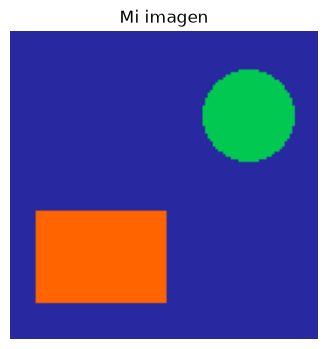

In [3]:
from PIL import Image, ImageDraw
# Completa: crea tu imagen con fondo y al menos 2 figuras
img = Image.new("RGB", (120, 120), color=(40, 40, 160))

draw = ImageDraw.Draw(img)

# Rectángulo naranja en la parte inferior izquierda
draw.rectangle(
    [10, 70, 60, 105],
    fill=(255, 100, 0)
)

# Círculo verde en la parte superior derecha
draw.ellipse(
    [75, 15, 110, 50],
    fill=(0, 200, 80)
)

print("Tamaño:", img.size)
print("Modo:", img.mode)

img.save("mi_imagen.png")
print("Archivo guardado: mi_imagen.png")

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title("Mi imagen")
plt.axis("off")
plt.show()

In [4]:
img2 = Image.open("mi_imagen.png")

# Coordenadas de Pillow: (x, y)
p_fondo = (5, 5)
p_rectangulo = (30, 85)
p_circulo = (90, 30)

print("Formato:", img2.format)
print("Tamaño:", img2.size)
print("Modo:", img2.mode)

print("Fondo", p_fondo, ":", img2.getpixel(p_fondo))
print("Rectángulo", p_rectangulo, ":", img2.getpixel(p_rectangulo))
print("Círculo", p_circulo, ":", img2.getpixel(p_circulo))

Formato: PNG
Tamaño: (120, 120)
Modo: RGB
Fondo (5, 5) : (40, 40, 160)
Rectángulo (30, 85) : (255, 100, 0)
Círculo (90, 30) : (0, 200, 80)


Escala de grises: (120, 120) | Modo: L
Rotación de 90°: (120, 120)
Redimensionamiento: (60, 60)
Volteo vertical: (120, 120)


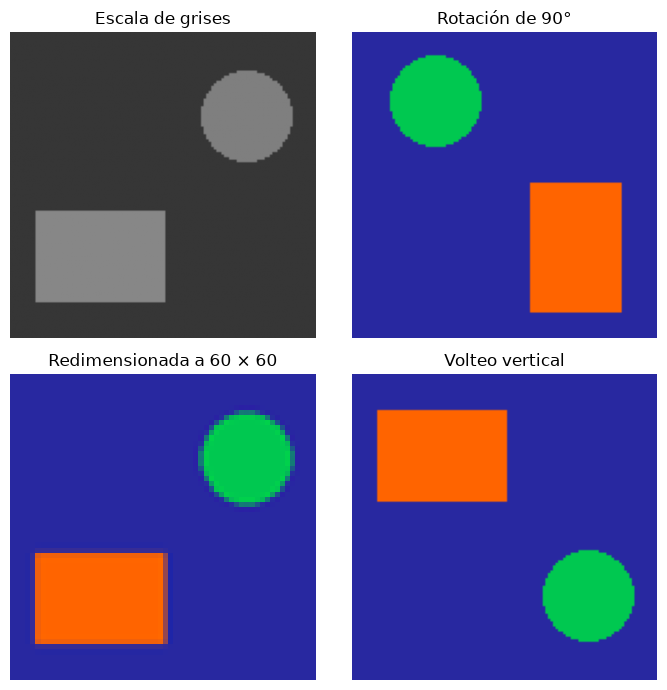

In [5]:
# Escala de grises
img_gris = img2.convert("L")

# Rotación de 90 grados
img_rotada = img2.rotate(90, expand=True)

# Redimensionamiento a la mitad
img_pequena = img2.resize(
    (img2.width // 2, img2.height // 2)
)

# Volteo vertical
img_volteada = img2.transpose(Image.Transpose.FLIP_TOP_BOTTOM)

print("Escala de grises:", img_gris.size, "| Modo:", img_gris.mode)
print("Rotación de 90°:", img_rotada.size)
print("Redimensionamiento:", img_pequena.size)
print("Volteo vertical:", img_volteada.size)

fig, axs = plt.subplots(2, 2, figsize=(7, 7))

imagenes = [img_gris, img_rotada, img_pequena, img_volteada]
titulos = [
    "Escala de grises",
    "Rotación de 90°",
    "Redimensionada a 60 × 60",
    "Volteo vertical"
]

for ax, imagen, titulo in zip(axs.flat, imagenes, titulos):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()


Píxel del rectángulo: (30, 85)
Antes: (255, 100, 0)
Sin recorte, al multiplicar por 3: (765, 300, 0)
Después con Pillow: (255, 255, 0)


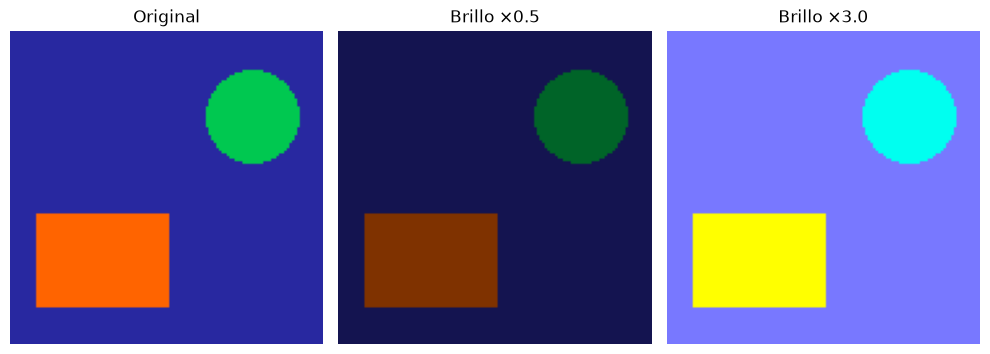

In [7]:
realzador = ImageEnhance.Brightness(img2)

img_oscura = realzador.enhance(0.5)
img_brillante = realzador.enhance(3.0)

antes = img2.getpixel(p_rectangulo)
despues = img_brillante.getpixel(p_rectangulo)

print("Píxel del rectángulo:", p_rectangulo)
print("Antes:", antes)
print("Sin recorte, al multiplicar por 3:", tuple(v * 3 for v in antes))
print("Después con Pillow:", despues)

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

imagenes = [img2, img_oscura, img_brillante]
titulos = ["Original", "Brillo ×0.5", "Brillo ×3.0"]

for ax, imagen, titulo in zip(axs, imagenes, titulos):
    ax.imshow(imagen)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Guardado: tema7_blur.png
Guardado: tema7_bordes.png


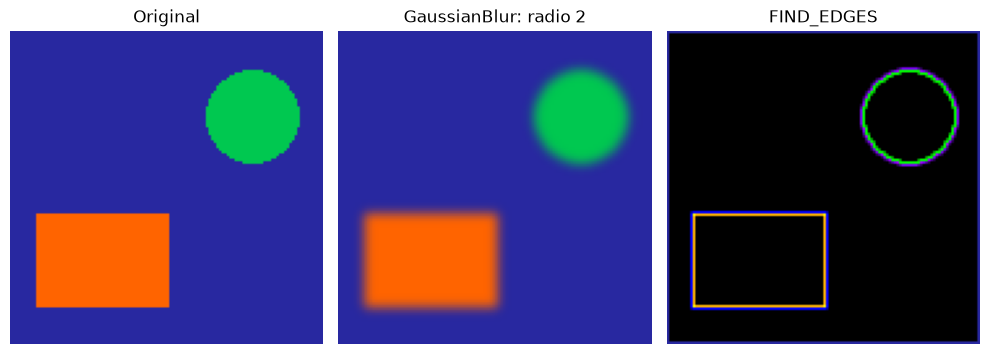

In [8]:
img_blur = img2.filter(ImageFilter.GaussianBlur(radius=2))
img_bordes = img2.filter(ImageFilter.FIND_EDGES)

img_blur.save("tema7_blur.png")
img_bordes.save("tema7_bordes.png")

print("Guardado: tema7_blur.png")
print("Guardado: tema7_bordes.png")

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

imagenes = [img2, img_blur, img_bordes]
titulos = ["Original", "GaussianBlur: radio 2", "FIND_EDGES"]

for ax, imagen, titulo in zip(axs, imagenes, titulos):
    ax.imshow(imagen)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()

Array RGB: (120, 120, 3) uint8
Pillow en grises: uint8
scikit-image en grises: float64
Coordenadas del fondo: (5, 5)
Pillow, escala 0–255: 54
scikit-image, escala 0–1: 0.190792
scikit-image multiplicado por 255: 48.652


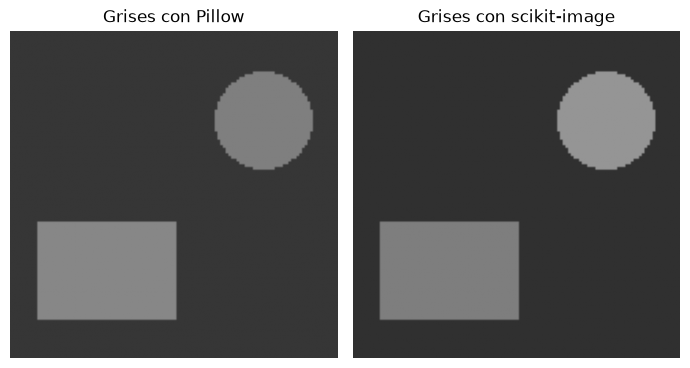

In [9]:
arr = np.array(img2)

# Escala de grises con scikit-image
gris_sk = color.rgb2gray(arr)

# Escala de grises con Pillow
gris_pil = np.array(img2.convert("L"))

# Pillow usa (x, y); NumPy se indexa como [y, x]
x, y = p_fondo

valor_pil = int(gris_pil[y, x])
valor_sk = float(gris_sk[y, x])

print("Array RGB:", arr.shape, arr.dtype)
print("Pillow en grises:", gris_pil.dtype)
print("scikit-image en grises:", gris_sk.dtype)

print("Coordenadas del fondo:", p_fondo)
print("Pillow, escala 0–255:", valor_pil)
print(f"scikit-image, escala 0–1: {valor_sk:.6f}")
print(f"scikit-image multiplicado por 255: {valor_sk * 255:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(7, 4))

axs[0].imshow(gris_pil, cmap="gray", vmin=0, vmax=255)
axs[0].set_title("Grises con Pillow")

axs[1].imshow(gris_sk, cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Grises con scikit-image")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

Umbral de Otsu: 0.1916
Tipo de binaria: bool
Proporción de píxeles True: 0.1978
Porcentaje de píxeles True: 19.78%


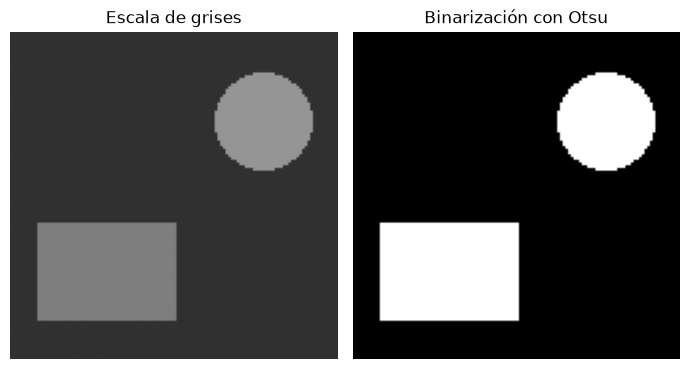

In [10]:
umbral_otsu = filters.threshold_otsu(gris_sk)

binaria = gris_sk > umbral_otsu

proporcion = float(binaria.mean())

print(f"Umbral de Otsu: {umbral_otsu:.4f}")
print("Tipo de binaria:", binaria.dtype)
print(f"Proporción de píxeles True: {proporcion:.4f}")
print(f"Porcentaje de píxeles True: {proporcion * 100:.2f}%")

fig, axs = plt.subplots(1, 2, figsize=(7, 4))

axs[0].imshow(gris_sk, cmap="gray", vmin=0, vmax=1)
axs[0].set_title("Escala de grises")

axs[1].imshow(binaria, cmap="gray", vmin=0, vmax=1)
axs[1].set_title("Binarización con Otsu")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

Umbral manual con Pillow: 100
Umbral automático con scikit-image: 0.1916


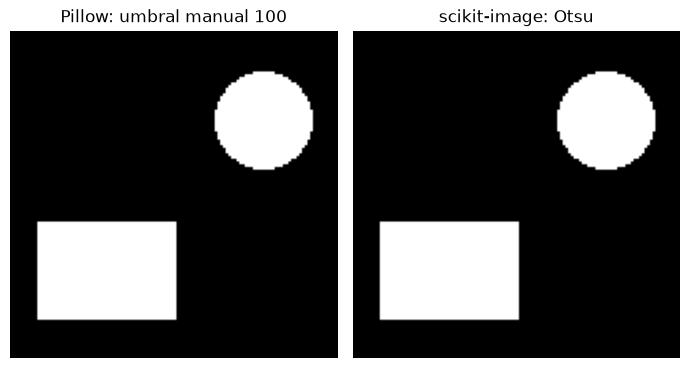

In [11]:
umbral_manual = 100

binaria_pil = img2.convert("L").point(
    lambda p: 255 if p > umbral_manual else 0
)

print("Umbral manual con Pillow:", umbral_manual)
print(f"Umbral automático con scikit-image: {umbral_otsu:.4f}")

fig, axs = plt.subplots(1, 2, figsize=(7, 4))

axs[0].imshow(binaria_pil, cmap="gray", vmin=0, vmax=255)
axs[0].set_title("Pillow: umbral manual 100")

axs[1].imshow(binaria, cmap="gray", vmin=0, vmax=1)
axs[1].set_title("scikit-image: Otsu")

for ax in axs:
    ax.axis("off")

plt.tight_layout()
plt.show()

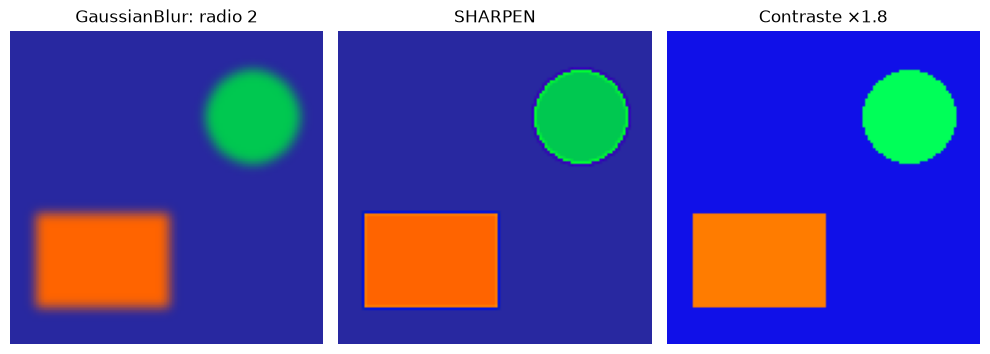

In [14]:
##RETO OPCIONAL
img_sharpen = img2.filter(ImageFilter.SHARPEN)
img_contraste = ImageEnhance.Contrast(img2).enhance(1.8)

fig, axs = plt.subplots(1, 3, figsize=(10, 4))

imagenes = [img_blur, img_sharpen, img_contraste]
titulos = [
    "GaussianBlur: radio 2",
    "SHARPEN",
    "Contraste ×1.8"
]

for ax, imagen, titulo in zip(axs, imagenes, titulos):
    ax.imshow(imagen)
    ax.set_title(titulo)
    ax.axis("off")

plt.tight_layout()
plt.show()